# [02] CAS(ME)² — Evaluasi IoU dan F1 Spotting

Membandingkan setiap interval hasil spotting dengan interval ground truth CAS(ME)²
menggunakan **Intersection over Union (IoU)**. Sebuah interval dinyatakan
**true positive apabila IoU dengan interval ground truth melebihi 0,5**.

Protokol metrik mengikuti MEGC (dipakai paper RMES 2023):

```
X_i = jumlah GT micro di video i
Y_i = jumlah interval hasil spotting di video i
a_i = jumlah true positive di video i

R  = sum(a_i) / sum(X_i)
P  = sum(a_i) / sum(Y_i)
F1 = 2PR / (P + R)
```

Matching **1-ke-1**: satu interval GT hanya boleh diklaim satu prediksi, dan sebaliknya.
Pasangan dipilih greedy dari IoU tertinggi ke terendah.

**Output** (`output/casme2/eval/`)
- `iou_matches.xlsx` — tiap interval spotting: TP/FP, IoU terbaik, GT pasangannya
- `iou_gt_coverage.xlsx` — tiap 57 GT: tertangkap atau tidak, IoU terbaik
- `f1_per_video.xlsx`, `f1_per_subject.xlsx`, `f1_summary.xlsx`
- `plots/` — distribusi IoU, TP/FP per video, perbandingan dengan literatur

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sns.set_theme(style='whitegrid')

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'casme2':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'casme2') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'casme2'))

import casme2_lib as cl

# Harus sama dengan [01]. False = evaluasi baseline tanpa face alignment.
config = cl.Casme2Config(project_root=PROJECT_ROOT, face_alignment=True)
PLOT_ROOT = config.eval_root / 'plots'
cl.ensure_dir(config.eval_root)
cl.ensure_dir(PLOT_ROOT)

print(f'OUTPUT        = {config.eval_root}')
print(f'FACE_ALIGN    = {config.face_alignment}')
print(f'IOU_THRESHOLD = {config.iou_threshold}')

OUTPUT        = /home/ryuko/skripsi/Skripsi/Convat-1st/output/casme2/eval_aligned
FACE_ALIGN    = True
IOU_THRESHOLD = 0.5


In [2]:
if not config.spotting_metadata_path.exists():
    raise FileNotFoundError(f'Jalankan [01] dulu: {config.spotting_metadata_path}')

metadata = pd.read_excel(config.spotting_metadata_path)
ground_truth = cl.load_ground_truth(config, micro_only=True)

# Hanya evaluasi video yang benar-benar diproses di [01]
processed_keys = sorted(metadata['video_key'].unique().tolist(), key=cl.natural_sort_key)
ground_truth = ground_truth[ground_truth['video_key'].isin(processed_keys)].reset_index(drop=True)

print(f'Video dievaluasi        : {len(processed_keys)}')
print(f'Interval spotting (sumY): {len(metadata)}')
print(f'GT micro (sum X)        : {len(ground_truth)}')
print(f'Rata-rata interval/video: {len(metadata) / max(len(processed_keys), 1):.1f}')

Video dievaluasi        : 33
Interval spotting (sumY): 1434
GT micro (sum X)        : 57
Rata-rata interval/video: 43.5


## Matching IoU per video

In [3]:
match_rows = []
coverage_rows = []
per_video_rows = []

for video_key in processed_keys:
    preds = metadata[metadata['video_key'] == video_key].reset_index(drop=True)
    gts = ground_truth[ground_truth['video_key'] == video_key].reset_index(drop=True)

    pred_intervals = list(zip(preds['onset_img'].astype(int), preds['offset_img'].astype(int)))
    gt_intervals = list(zip(gts['onset'].astype(int), gts['offset'].astype(int)))

    pairs, used_pred, used_gt = cl.match_intervals(
        pred_intervals, gt_intervals, iou_threshold=config.iou_threshold
    )
    gt_by_pred = {pi: (gi, iou_value) for pi, gi, iou_value in pairs}

    # --- satu baris per interval hasil spotting ---
    for pi, pred in preds.iterrows():
        best_iou, best_gi = 0.0, None
        for gi, gt_interval in enumerate(gt_intervals):
            value = cl.compute_iou(pred_intervals[pi], gt_interval)
            if value > best_iou:
                best_iou, best_gi = value, gi
        matched_gi, matched_iou = gt_by_pred.get(pi, (None, None))
        is_tp = pi in used_pred
        match_rows.append({
            'video_key': video_key,
            'subject': pred['subject'],
            'video': pred['video'],
            'event_clip': pred['event_clip'],
            'pred_onset': int(pred['onset_img']),
            'pred_offset': int(pred['offset_img']),
            'pred_apex': int(pred['apex_img']),
            'pred_duration': int(pred['duration_img']),
            'status': 'TP' if is_tp else 'FP',
            'matched_clip_name': gts.iloc[matched_gi]['clip_name'] if matched_gi is not None else None,
            'matched_emotion': gts.iloc[matched_gi]['emotion'] if matched_gi is not None else None,
            'matched_iou': float(matched_iou) if matched_iou is not None else None,
            'best_iou_any': float(best_iou),
            'best_gt_clip': gts.iloc[best_gi]['clip_name'] if best_gi is not None else None,
        })

    # --- satu baris per GT micro ---
    for gi, gt in gts.iterrows():
        best_iou, best_pi = 0.0, None
        for pi, pred_interval in enumerate(pred_intervals):
            value = cl.compute_iou(pred_interval, gt_intervals[gi])
            if value > best_iou:
                best_iou, best_pi = value, pi
        coverage_rows.append({
            'video_key': video_key,
            'subject': gt['subject'],
            'clip_name': gt['clip_name'],
            'emotion': gt['emotion'],
            'gt_onset': int(gt['onset']),
            'gt_apex': int(gt['apex']),
            'gt_offset': int(gt['offset']),
            'gt_duration': int(gt['duration']),
            'detected': gi in used_gt,
            'best_iou': float(best_iou),
            'best_pred_clip': preds.iloc[best_pi]['event_clip'] if best_pi is not None else None,
            'best_pred_onset': int(preds.iloc[best_pi]['onset_img']) if best_pi is not None else None,
            'best_pred_offset': int(preds.iloc[best_pi]['offset_img']) if best_pi is not None else None,
        })

    per_video_rows.append({
        'video_key': video_key,
        'subject': preds['subject'].iloc[0] if len(preds) else video_key.split('/')[0],
        'X_gt': len(gt_intervals),
        'Y_pred': len(pred_intervals),
        'a_tp': len(pairs),
    })

matches = pd.DataFrame(match_rows)
coverage = pd.DataFrame(coverage_rows)
per_video = pd.DataFrame(per_video_rows)

matches.to_excel(config.eval_root / 'iou_matches.xlsx', index=False)
coverage.to_excel(config.eval_root / 'iou_gt_coverage.xlsx', index=False)

print(f"TP : {(matches['status'] == 'TP').sum()}")
print(f"FP : {(matches['status'] == 'FP').sum()}")
print(f"FN : {(~coverage['detected']).sum()}")
coverage.head()

TP : 16
FP : 1418
FN : 41


,video_key,subject,clip_name,emotion,gt_onset,gt_apex,gt_offset,gt_duration,detected,best_iou,best_pred_clip,best_pred_onset,best_pred_offset
0,s15/15_0102eatingworms,s15,disgust2_3,negative,699,703,707,9,False,0.148148,event_00681-00702,681.0,702.0
1,s15/15_0502funnyerrors,s15,happy1_1,positive,138,142,148,11,False,0.000000,None,NaN,NaN
2,s16/16_0101disgustingteeth,s16,disgust1_3,negative,552,559,565,14,True,0.650000,event_00553-00571,553.0,571.0
3,s16/16_0102eatingworms,s16,disgust2_3,negative,270,275,278,9,False,0.000000,None,NaN,NaN
4,s16/16_0502funnyerrors,s16,happy1_1,positive,323,329,334,12,False,0.000000,None,NaN,NaN


## Metrik F1 spotting

In [4]:
TP = int(per_video['a_tp'].sum())
X = int(per_video['X_gt'].sum())
Y = int(per_video['Y_pred'].sum())

overall = cl.spotting_f1(TP, X, Y)

summary = pd.DataFrame([{
    'n_video': len(per_video),
    'sum_X_gt': overall['n_ground_truth'],
    'sum_Y_pred': overall['n_predicted'],
    'TP': overall['TP'],
    'FP': overall['FP'],
    'FN': overall['FN'],
    'precision': overall['precision'],
    'recall': overall['recall'],
    'f1': overall['f1'],
    'iou_threshold': config.iou_threshold,
    'alpha': config.alpha,
    'top_k_apex': config.top_k_apex,
    'min_phase_duration': config.min_phase_duration,
}])

per_video['precision'] = per_video['a_tp'] / per_video['Y_pred'].replace(0, np.nan)
per_video['recall'] = per_video['a_tp'] / per_video['X_gt'].replace(0, np.nan)

per_subject = per_video.groupby('subject')[['X_gt', 'Y_pred', 'a_tp']].sum().reset_index()
per_subject['precision'] = per_subject['a_tp'] / per_subject['Y_pred'].replace(0, np.nan)
per_subject['recall'] = per_subject['a_tp'] / per_subject['X_gt'].replace(0, np.nan)
per_subject['f1'] = 2 * per_subject['precision'] * per_subject['recall'] / (
    per_subject['precision'] + per_subject['recall']).replace(0, np.nan)

per_video.to_excel(config.eval_root / 'f1_per_video.xlsx', index=False)
per_subject.to_excel(config.eval_root / 'f1_per_subject.xlsx', index=False)
summary.to_excel(config.eval_root / 'f1_summary.xlsx', index=False)

print('=' * 58)
print('   F1 SPOTTING MICRO-EXPRESSION — CAS(ME)^2')
print('=' * 58)
print(f"  Ground truth (sum X) : {overall['n_ground_truth']}")
print(f"  Terdeteksi   (sum Y) : {overall['n_predicted']}")
print(f"  True Positive        : {overall['TP']}")
print(f"  False Positive       : {overall['FP']}")
print(f"  False Negative       : {overall['FN']}")
print('-' * 58)
print(f"  Precision            : {overall['precision']:.4f}")
print(f"  Recall               : {overall['recall']:.4f}")
print(f"  F1-score             : {overall['f1']:.4f}")
print('=' * 58)
summary

   F1 SPOTTING MICRO-EXPRESSION — CAS(ME)^2
  Ground truth (sum X) : 57
  Terdeteksi   (sum Y) : 1434
  True Positive        : 16
  False Positive       : 1418
  False Negative       : 41
----------------------------------------------------------
  Precision            : 0.0112
  Recall               : 0.2807
  F1-score             : 0.0215


,n_video,sum_X_gt,sum_Y_pred,TP,FP,FN,precision,recall,f1,iou_threshold,alpha,top_k_apex,min_phase_duration
0,33,57,1434,16,1418,41,0.011158,0.280702,0.021462,0.5,1.0,0,2


## Perbandingan dengan literatur

Angka F1 spotting micro-expression CAS(ME)² dari paper RMES (Fang et al., 2023), Tabel II.

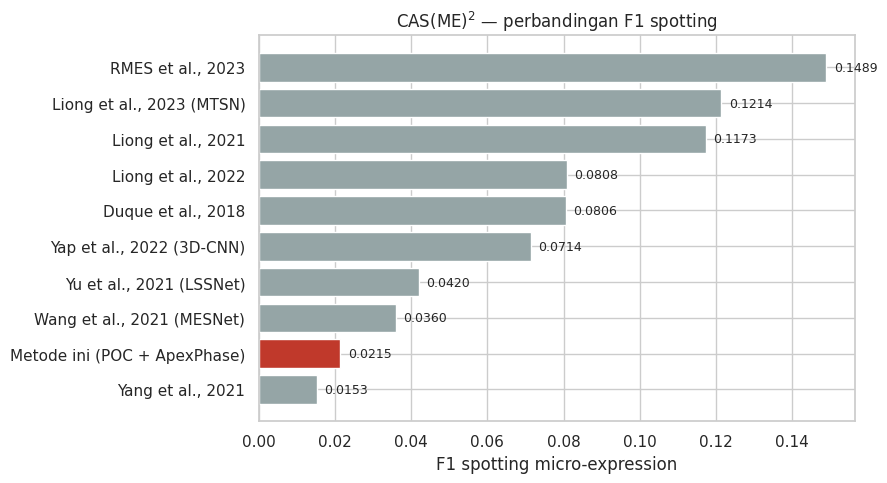

,metode,F1
0,"RMES et al., 2023",0.148900
1,"Liong et al., 2023 (MTSN)",0.121400
2,"Liong et al., 2021",0.117300
3,"Liong et al., 2022",0.080800
4,"Duque et al., 2018",0.080600
5,"Yap et al., 2022 (3D-CNN)",0.071400
6,"Yu et al., 2021 (LSSNet)",0.042000
7,"Wang et al., 2021 (MESNet)",0.036000
8,Metode ini (POC + ApexPhase),0.021462
9,"Yang et al., 2021",0.015300


In [5]:
bench = pd.DataFrame(
    [{'metode': k, 'F1': v} for k, v in cl.SOTA_F1_CASME2.items()]
    + [{'metode': 'Metode ini (POC + ApexPhase)', 'F1': overall['f1']}]
).sort_values('F1', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#c0392b' if 'Metode ini' in m else '#95a5a6' for m in bench['metode']]
ax.barh(bench['metode'], bench['F1'], color=colors)
ax.invert_yaxis()
ax.set_xlabel('F1 spotting micro-expression')
ax.set_title('CAS(ME)$^2$ — perbandingan F1 spotting')
for i, v in enumerate(bench['F1']):
    ax.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
fig.tight_layout()
fig.savefig(PLOT_ROOT / 'f1_vs_sota.png', dpi=200, bbox_inches='tight')
plt.show()

bench

## Distribusi IoU

Menunjukkan seberapa dekat interval hasil spotting dengan ground truth, termasuk yang gagal
melewati ambang 0,5. Berguna untuk pembahasan: apakah metode meleset jauh, atau nyaris kena.

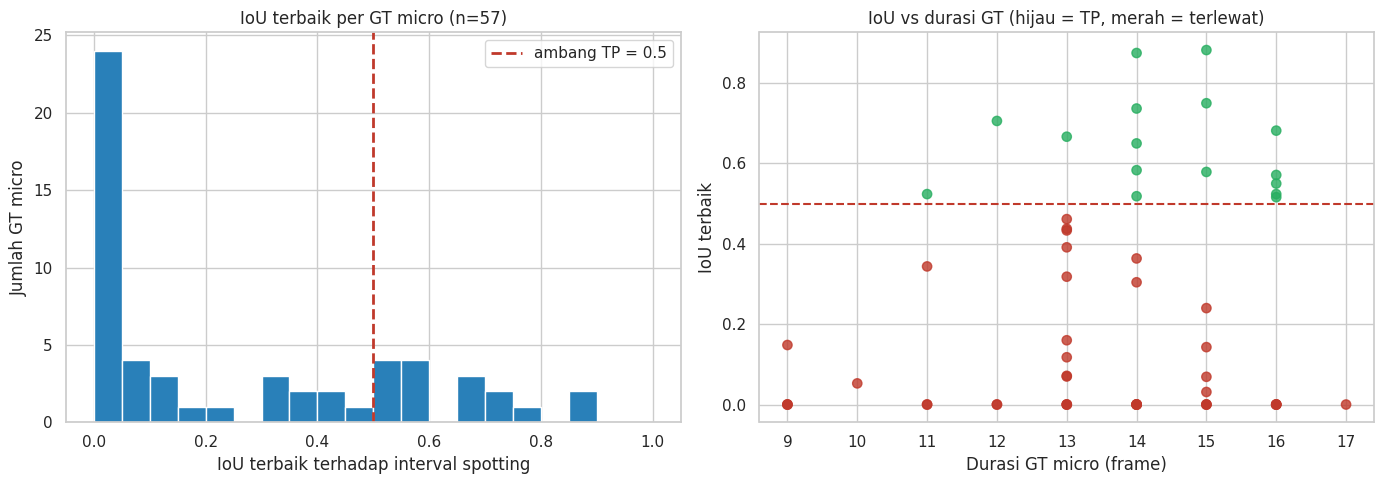

IoU terbaik  median : 0.118
IoU terbaik  maksimum: 0.882
GT dengan IoU > 0.5 : 16 / 57
GT tanpa overlap    : 23 / 57


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(coverage['best_iou'], bins=20, range=(0, 1), color='#2980b9', edgecolor='white')
axes[0].axvline(config.iou_threshold, color='#c0392b', linestyle='--', linewidth=2,
                label=f'ambang TP = {config.iou_threshold}')
axes[0].set_xlabel('IoU terbaik terhadap interval spotting')
axes[0].set_ylabel('Jumlah GT micro')
axes[0].set_title(f'IoU terbaik per GT micro (n={len(coverage)})')
axes[0].legend()

axes[1].scatter(coverage['gt_duration'], coverage['best_iou'],
                c=coverage['detected'].map({True: '#27ae60', False: '#c0392b'}), s=45, alpha=0.8)
axes[1].axhline(config.iou_threshold, color='#c0392b', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Durasi GT micro (frame)')
axes[1].set_ylabel('IoU terbaik')
axes[1].set_title('IoU vs durasi GT (hijau = TP, merah = terlewat)')

fig.tight_layout()
fig.savefig(PLOT_ROOT / 'iou_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"IoU terbaik  median : {coverage['best_iou'].median():.3f}")
print(f"IoU terbaik  maksimum: {coverage['best_iou'].max():.3f}")
print(f"GT dengan IoU > 0.5 : {(coverage['best_iou'] > config.iou_threshold).sum()} / {len(coverage)}")
print(f"GT tanpa overlap    : {(coverage['best_iou'] == 0).sum()} / {len(coverage)}")

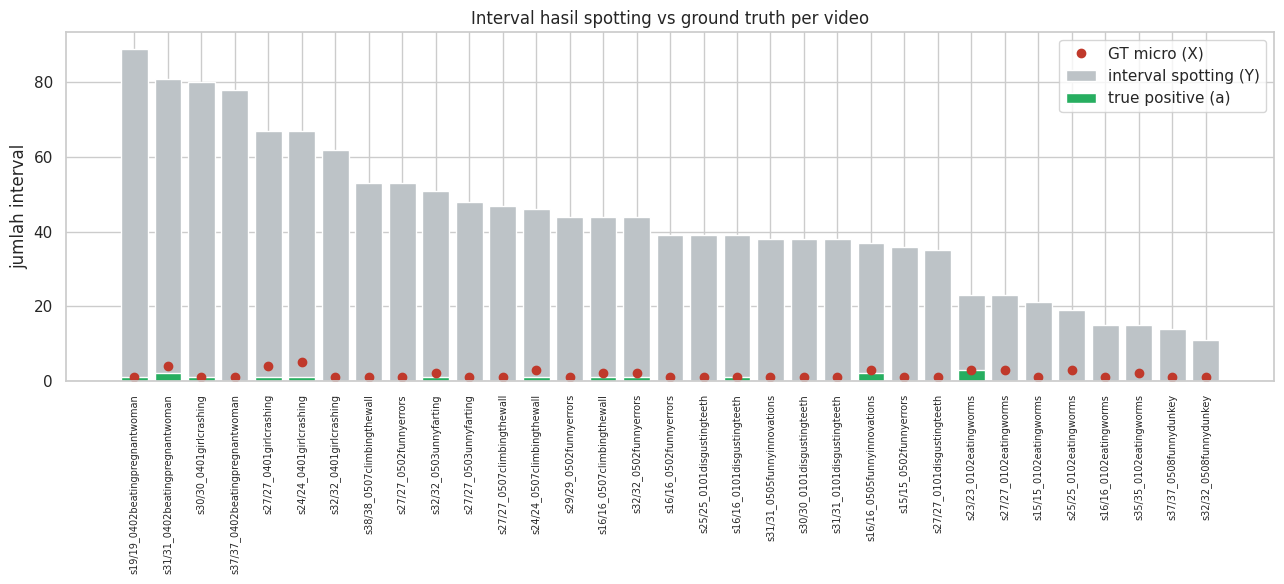

,video_key,subject,X_gt,Y_pred,a_tp,precision,recall
8,s23/23_0102eatingworms,s23,3,23,3,0.130435,1.000000
23,s31/31_0402beatingpregnantwoman,s31,4,81,2,0.024691,0.500000
5,s16/16_0505funnyinnovations,s16,3,37,2,0.054054,0.666667
26,s32/32_0502funnyerrors,s32,2,44,1,0.022727,0.500000
2,s16/16_0101disgustingteeth,s16,1,39,1,0.025641,1.000000
7,s19/19_0402beatingpregnantwoman,s19,1,89,1,0.011236,1.000000
15,s27/27_0401girlcrashing,s27,4,67,1,0.014925,0.250000
10,s24/24_0507climbingthewall,s24,3,46,1,0.021739,0.333333
6,s16/16_0507climbingthewall,s16,2,44,1,0.022727,0.500000
21,s30/30_0401girlcrashing,s30,1,80,1,0.012500,1.000000


In [7]:
fig, ax = plt.subplots(figsize=(13, 6))
plot_df = per_video.sort_values('Y_pred', ascending=False)
ax.bar(range(len(plot_df)), plot_df['Y_pred'], color='#bdc3c7', label='interval spotting (Y)')
ax.bar(range(len(plot_df)), plot_df['a_tp'], color='#27ae60', label='true positive (a)')
ax.plot(range(len(plot_df)), plot_df['X_gt'], 'o', color='#c0392b', markersize=6, label='GT micro (X)')
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df['video_key'], rotation=90, fontsize=7)
ax.set_ylabel('jumlah interval')
ax.set_title('Interval hasil spotting vs ground truth per video')
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_ROOT / 'per_video_intervals.png', dpi=200, bbox_inches='tight')
plt.show()

per_video.sort_values('a_tp', ascending=False).head(10)

## Lebar interval: spotting vs ground truth

IoU sangat sensitif terhadap selisih lebar interval. Kalau interval hasil spotting jauh lebih
lebar daripada GT, IoU tidak akan pernah melewati 0,5 walaupun posisinya sudah benar.

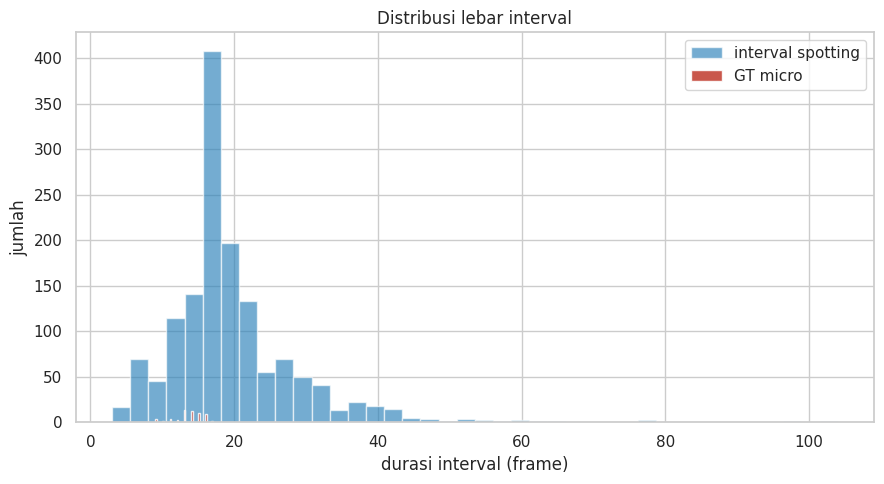

Lebar interval spotting: median 18 frame (min 3, max 104)
Lebar GT micro         : median 14 frame (min 9, max 17)


In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(matches['pred_duration'], bins=40, alpha=0.65, label='interval spotting', color='#2980b9')
ax.hist(coverage['gt_duration'], bins=40, alpha=0.85, label='GT micro', color='#c0392b')
ax.set_xlabel('durasi interval (frame)')
ax.set_ylabel('jumlah')
ax.set_title('Distribusi lebar interval')
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_ROOT / 'interval_width.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Lebar interval spotting: median {matches['pred_duration'].median():.0f} frame "
      f"(min {matches['pred_duration'].min()}, max {matches['pred_duration'].max()})")
print(f"Lebar GT micro         : median {coverage['gt_duration'].median():.0f} frame "
      f"(min {coverage['gt_duration'].min()}, max {coverage['gt_duration'].max()})")

## Ablation — pengaruh face alignment

Membandingkan varian dengan dan tanpa face alignment, meniru Tabel V paper RMES.
Sel ini butuh **kedua** varian sudah dijalankan di `[01]`
(`face_alignment=True` dan `face_alignment=False`); kalau salah satu belum ada, sel dilewati.

Sinyal kedua varian tersimpan di folder terpisah, jadi tidak saling menimpa.

In [9]:
def evaluate_variant(face_alignment: bool) -> dict | None:
    variant_config = cl.Casme2Config(project_root=PROJECT_ROOT, face_alignment=face_alignment)
    if not variant_config.spotting_metadata_path.exists():
        return None

    variant_meta = pd.read_excel(variant_config.spotting_metadata_path)
    variant_gt = cl.load_ground_truth(variant_config, micro_only=True)
    keys = sorted(variant_meta['video_key'].unique().tolist(), key=cl.natural_sort_key)
    variant_gt = variant_gt[variant_gt['video_key'].isin(keys)]

    total_tp = total_gt = total_pred = 0
    widths = []
    for key in keys:
        preds = variant_meta[variant_meta['video_key'] == key]
        gts = variant_gt[variant_gt['video_key'] == key]
        pred_intervals = list(zip(preds['onset_img'].astype(int), preds['offset_img'].astype(int)))
        gt_intervals = list(zip(gts['onset'].astype(int), gts['offset'].astype(int)))
        pairs, _, _ = cl.match_intervals(pred_intervals, gt_intervals, variant_config.iou_threshold)
        total_tp += len(pairs)
        total_gt += len(gt_intervals)
        total_pred += len(pred_intervals)
        widths += [b - a + 1 for a, b in pred_intervals]

    result = cl.spotting_f1(total_tp, total_gt, total_pred)
    result['face_alignment'] = face_alignment
    result['n_video'] = len(keys)
    result['lebar_median'] = float(np.median(widths)) if widths else 0.0
    return result


ablation_rows = [r for r in (evaluate_variant(False), evaluate_variant(True)) if r is not None]

if len(ablation_rows) < 2:
    have = [r['face_alignment'] for r in ablation_rows]
    print('Ablation dilewati: baru varian face_alignment='
          f'{have} yang tersedia.')
    print('Jalankan [01] untuk varian yang lain supaya tabel ini terisi.')
else:
    ablation = pd.DataFrame(ablation_rows)[
        ['face_alignment', 'n_video', 'n_ground_truth', 'n_predicted',
         'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'lebar_median']
    ]
    ablation.to_excel(config.eval_root / 'ablation_face_alignment.xlsx', index=False)

    base = ablation[~ablation['face_alignment']].iloc[0]
    algn = ablation[ablation['face_alignment']].iloc[0]
    delta = (algn['f1'] - base['f1']) / base['f1'] * 100 if base['f1'] else float('nan')

    print('=' * 60)
    print('  ABLATION — face alignment (bandingkan RMES 2023 Tabel V)')
    print('=' * 60)
    print(ablation.to_string(index=False))
    print('-' * 60)
    print(f"  FP  : {int(base['FP'])} -> {int(algn['FP'])}")
    print(f"  F1  : {base['f1']:.4f} -> {algn['f1']:.4f}  ({delta:+.1f}%)")
    print('=' * 60)
    display(ablation)

  ABLATION — face alignment (bandingkan RMES 2023 Tabel V)
 face_alignment  n_video  n_ground_truth  n_predicted  TP   FP  FN  precision   recall       f1  lebar_median
          False       33              57         1389  15 1374  42   0.010799 0.263158 0.020747          18.0
           True       33              57         1434  16 1418  41   0.011158 0.280702 0.021462          18.0
------------------------------------------------------------
  FP  : 1374 -> 1418
  F1  : 0.0207 -> 0.0215  (+3.4%)


,face_alignment,n_video,n_ground_truth,n_predicted,TP,FP,FN,precision,recall,f1,lebar_median
0,False,33,57,1389,15,1374,42,0.010799,0.263158,0.020747,18.0
1,True,33,57,1434,16,1418,41,0.011158,0.280702,0.021462,18.0


## Plot zoom per GT micro

Satu gambar untuk tiap ground truth micro-expression, dengan jendela ±150 frame di sekitarnya.
Skala jadi setara plot dataset anxiety, sehingga bentuk gelombangnya terbaca — plot video penuh
menjejalkan 3.000+ frame ke lebar yang sama, jadi kelihatan kusut padahal kerapatan osilasinya
sama saja.

- **pita hijau** — interval ground truth
- **pita oranye** — interval hasil spotting yang beririsan dengan jendela
- **titik merah** — apex hasil spotting
- **judul** — IoU terbaik dan status TP / MISS

Ini gambar yang menjawab pertanyaan penguji: bukan sekadar berapa F1-nya, tapi *kenapa*
sebuah micro tertangkap atau terlewat.

In [10]:
ZOOM_MARGIN = 150
GT_ZOOM_ROOT = PLOT_ROOT / 'gt_zoom'
cl.ensure_dir(GT_ZOOM_ROOT)

_signal_cache = {}


def load_signal(video_key: str):
    # Sinyal per video di-cache supaya tidak dibaca ulang untuk tiap GT.
    if video_key not in _signal_cache:
        path = config.signal_root / f'{video_key}.xlsx'
        _signal_cache[video_key] = pd.read_excel(path) if path.exists() else None
    return _signal_cache[video_key]


def draw_gt_zoom(gt_row, ax) -> bool:
    signal_df = load_signal(gt_row['video_key'])
    if signal_df is None:
        ax.set_visible(False)
        return False

    lo = max(int(signal_df['img_number'].min()), int(gt_row['gt_onset']) - ZOOM_MARGIN)
    hi = min(int(signal_df['img_number'].max()), int(gt_row['gt_offset']) + ZOOM_MARGIN)
    window = signal_df[(signal_df['img_number'] >= lo) & (signal_df['img_number'] <= hi)]
    if window.empty:
        ax.set_visible(False)
        return False

    ax.plot(window['img_number'], window['smoothed_magnitude'],
            color='#1f4e9c', linewidth=1.4, zorder=3)
    ax.axhline(float(window['height_threshold'].iloc[0]), color='gray',
               linestyle='--', linewidth=1, alpha=0.7, zorder=1)

    # interval hasil spotting yang menyentuh jendela ini
    preds = matches[(matches['video_key'] == gt_row['video_key'])
                    & (matches['pred_offset'] >= lo)
                    & (matches['pred_onset'] <= hi)]
    for _, pred in preds.iterrows():
        ax.axvspan(pred['pred_onset'], pred['pred_offset'],
                   color='#f39c12', alpha=0.30, zorder=2)
        apex_row = window[window['img_number'] == pred['pred_apex']]
        if not apex_row.empty:
            ax.plot(pred['pred_apex'], apex_row['smoothed_magnitude'].iloc[0],
                    'o', color='#c0392b', markersize=5, zorder=4)

    # ground truth digambar paling atas supaya tidak tertutup pita oranye
    ax.axvspan(gt_row['gt_onset'], gt_row['gt_offset'],
               color='#27ae60', alpha=0.45, zorder=5)
    ax.axvline(gt_row['gt_apex'], color='#145a32', linestyle=':', linewidth=1.5, zorder=6)

    status = 'TP' if gt_row['detected'] else 'MISS'
    color = '#27ae60' if gt_row['detected'] else '#c0392b'
    title = (f"{gt_row['subject']} / {gt_row['clip_name']} ({gt_row['emotion']})  "
             f"GT {int(gt_row['gt_onset'])}-{int(gt_row['gt_offset'])} "
             f"({int(gt_row['gt_duration'])} frame)  |  "
             f"IoU={gt_row['best_iou']:.3f}  {status}")
    ax.set_title(title, fontsize=9, color=color)
    ax.set_xlabel('nomor frame (img)', fontsize=8)
    ax.set_ylabel('magnitude', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)
    return True


ZOOM_LEGEND = [
    Patch(facecolor='#27ae60', alpha=0.45, label='ground truth micro'),
    Patch(facecolor='#f39c12', alpha=0.30, label='interval spotting'),
    Line2D([0], [0], color='#1f4e9c', linewidth=1.4, label='sinyal (smoothed)'),
    Line2D([0], [0], marker='o', color='#c0392b', linestyle='', markersize=5, label='apex spotting'),
    Line2D([0], [0], color='gray', linestyle='--', label='ambang mean+1sigma'),
]

saved = 0
for _, gt_row in coverage.iterrows():
    fig, ax = plt.subplots(figsize=(9, 3.2))
    if draw_gt_zoom(gt_row, ax):
        ax.legend(handles=ZOOM_LEGEND, loc='upper right', fontsize=6.5, framealpha=0.9)
        fig.tight_layout()
        fig.savefig(GT_ZOOM_ROOT / f"{gt_row['subject']}__{gt_row['clip_name']}.png",
                    dpi=160, bbox_inches='tight')
        saved += 1
    plt.close(fig)

print(f'{saved} plot zoom disimpan di: {GT_ZOOM_ROOT}')

57 plot zoom disimpan di: /home/ryuko/skripsi/Skripsi/Convat-1st/output/casme2/eval_aligned/plots/gt_zoom


### Empat contoh terpilih untuk bab pembahasan

Dua GT dengan IoU tertinggi yang tertangkap, dan dua yang paling nyaris lolos.
Perbandingan berdampingan ini menunjukkan apa yang membedakan kena dan meleset —
umumnya soal lebar interval, bukan posisi apex.

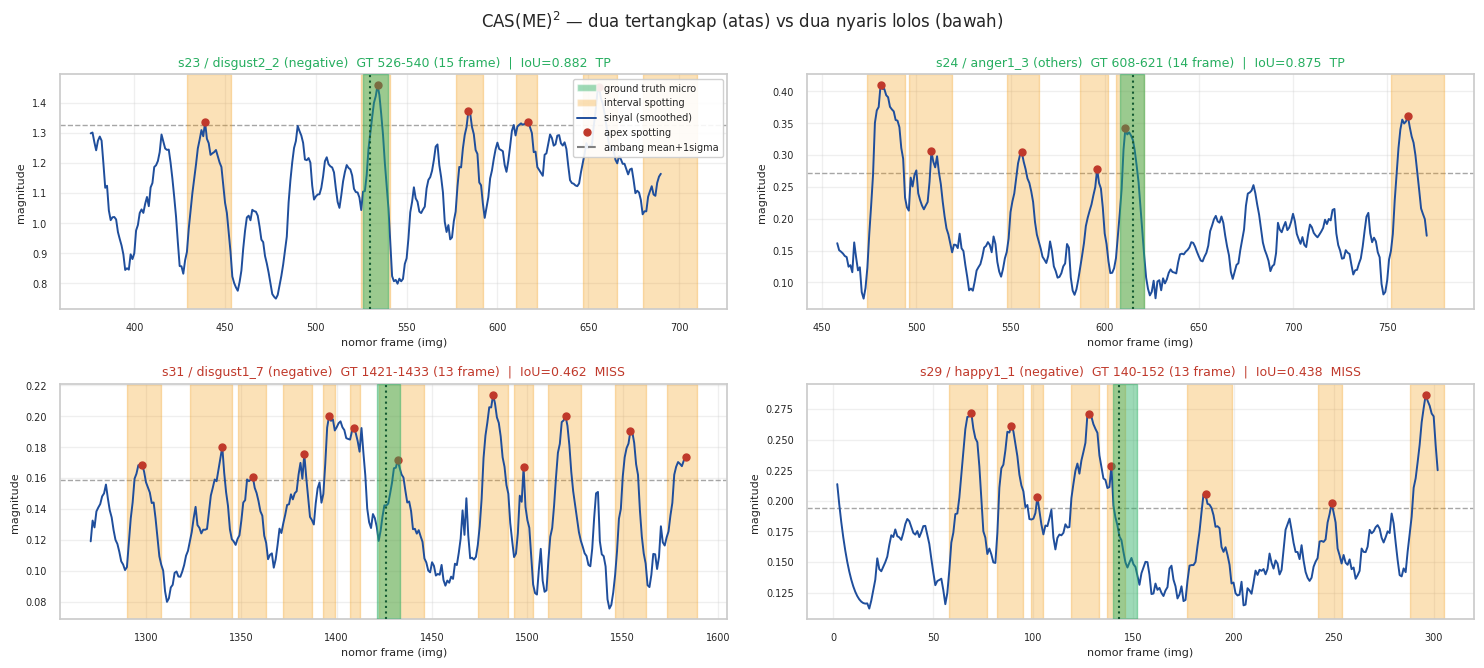

subject  clip_name  emotion  gt_onset  gt_offset  gt_duration  best_pred_onset  best_pred_offset  best_iou  detected
    s23 disgust2_2 negative       526        540           15            525.0             541.0  0.882353      True
    s24   anger1_3   others       608        621           14            606.0             621.0  0.875000      True
    s31 disgust1_7 negative      1421       1433           13           1422.0            1446.0  0.461538     False
    s29   happy1_1 negative       140        152           13            137.0             146.0  0.437500     False


In [11]:
best_tp = coverage[coverage['detected']].nlargest(2, 'best_iou')
near_miss = coverage[~coverage['detected']].nlargest(2, 'best_iou')
showcase = pd.concat([best_tp, near_miss])

if showcase.empty:
    print('Belum ada GT untuk ditampilkan.')
else:
    n = len(showcase)
    n_rows = (n + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 3.4 * n_rows), squeeze=False)
    flat = axes.ravel()
    for ax, (_, gt_row) in zip(flat, showcase.iterrows()):
        draw_gt_zoom(gt_row, ax)
    for ax in flat[n:]:
        ax.set_visible(False)
    flat[0].legend(handles=ZOOM_LEGEND, loc='upper right', fontsize=7, framealpha=0.9)
    fig.suptitle('CAS(ME)$^2$ — dua tertangkap (atas) vs dua nyaris lolos (bawah)', fontsize=12)
    fig.tight_layout()
    fig.savefig(PLOT_ROOT / 'gt_zoom_showcase.png', dpi=200, bbox_inches='tight')
    plt.show()

    print(showcase[['subject', 'clip_name', 'emotion', 'gt_onset', 'gt_offset', 'gt_duration',
                    'best_pred_onset', 'best_pred_offset', 'best_iou', 'detected']].to_string(index=False))

## GT yang tertangkap dan yang terlewat

In [12]:
detected = coverage[coverage['detected']].sort_values('best_iou', ascending=False)
missed = coverage[~coverage['detected']].sort_values('best_iou', ascending=False)

print(f'--- TERTANGKAP ({len(detected)}) ---')
if len(detected):
    print(detected[['subject', 'clip_name', 'emotion', 'gt_onset', 'gt_offset',
                    'best_pred_onset', 'best_pred_offset', 'best_iou']].to_string(index=False))

print(f'\n--- TERLEWAT, 10 yang paling mendekati (dari {len(missed)}) ---')
print(missed[['subject', 'clip_name', 'emotion', 'gt_onset', 'gt_offset',
              'best_pred_onset', 'best_pred_offset', 'best_iou']].head(10).to_string(index=False))

print(f'\nSemua artefak evaluasi tersimpan di: {config.eval_root}')
print('Lanjut ke [03] untuk ekstraksi fitur POC-ABS.')

--- TERTANGKAP (16) ---
subject  clip_name  emotion  gt_onset  gt_offset  best_pred_onset  best_pred_offset  best_iou
    s23 disgust2_2 negative       526        540            525.0             541.0  0.882353
    s24   anger1_3   others       608        621            606.0             621.0  0.875000
    s32   happy2_1 positive       258        272            258.0             277.0  0.750000
    s27   anger1_1   others       352        365            350.0             368.0  0.736842
    s16   happy3_2 positive       396        407            391.0             407.0  0.705882
    s30   anger1_2   others       926        941            927.0             947.0  0.681818
    s31   anger2_6   others      2377       2389           2375.0            2386.0  0.666667
    s16 disgust1_3 negative       552        565            553.0             571.0  0.650000
    s23 disgust2_3 negative       727        740            722.0             745.0  0.583333
    s31   anger2_4   others      219